# Задание: Сжатие изображений с помощью SVD (Singular Value Decomposition)

## 1. Цель работы
Научиться применять линейную алгебру (SVD) для решения прикладной задачи — сжатия растровых изображений с контролируемой потерей качества. Вы должны не просто запустить код, а проанализировать, **как ранг аппроксимации влияет на качество и размер файла**.

## 2. Теоретическая справка (кратко)
Любую матрицу $ A $ размером $ m \times n $ можно разложить на три матрицы:
$
A = U \cdot \Sigma \cdot V^T
$
Где:
- $ U $ — ортогональная матрица размера $ m \times m $ (левые сингулярные векторы).
- $ \Sigma $ — диагональная матрица размера $ m \times n $, на диагонали которой стоят сингулярные числа $ \sigma_1 \ge \sigma_2 \ge ... \ge \sigma_k $.
- $ V^T $ — ортогональная матрица размера $ n \times n $ (правые сингулярные векторы).

**Идея сжатия:** Если оставить только первые $ r $ сингулярных чисел (и соответствующие столбцы U и V), мы получим матрицу $ A_r $, которая является наилучшим приближением $ A $ среди всех матриц ранга $ r $ (в смысле нормы Фробениуса).

## 3. Техническое задание (Пошаговый план)

### Часть А. Загрузка и подготовка данных (Базовый уровень)
1. **Выбор изображения:**
   - Загрузите любую картинку (можно стандартный `lena` или `peppers`, либо свою фотографию).
   - *Усложнение:* Картинка должна быть цветной, размером не менее 300x300 пикселей.
2. **Чтение файла:**
   - Используйте `PIL.Image.open()` или `matplotlib.image.imread()`.
3. **Преобразование в массив:**
   - Переведите картинку в формат `numpy.ndarray`.
4. **Работа с цветом (выбор стратегии):**
   - *Вариант А (простой):* Переведите изображение в градации серого (одноканальное) с помощью `.convert('L')` или формулы `Gray = 0.299*R + 0.587*G + 0.114*B`. Тогда у вас будет одна матрица $ A $ размером $ height \times width $.
   - *Вариант Б (продвинутый):* Оставьте 3 цветовых канала (RGB). Примените SVD отдельно к матрице **каждого** канала (Red, Green, Blue). Затем соберите их обратно.

### Часть Б. Применение SVD и восстановление
1. **Разложение:**
   - Используйте функцию `np.linalg.svd(матрица, full_matrices=False)`.
   - *Внимание:* Параметр `full_matrices=False` важен для экономии памяти, иначе матрица $ U $ получится слишком большой.
2. **Сжатие (аппроксимация) для разных рангов:**
   - Восстановите изображение, используя только `r` сингулярных чисел.
   - Обязательные значения `r`: **[1, 5, 10, 30, 100, min(shape)]** (где последнее — полное восстановление без потерь).
   - Формула восстановления:
     $
     A_{approx} = U[:, :r] \cdot diag(\Sigma[:r]) \cdot V[:r, :]^T
     $
   - *Подсказка:* `np.diag(s[:r])` создаст диагональную матрицу, но для ускорения лучше использовать `(U[:, :r] * s[:r]) @ V[:r, :]`.

### Часть В. Визуализация результатов
- Создайте один большой график (subplot) размером 2x3 или 3x2.
- На каждом подграфике отобразите восстановленное изображение.
- **Подпишите** каждый подграфик строкой: `"Ранг = r, Сжатие в X раз"`.
- Оригинальное изображение выведите отдельно (или как самый последний график).

### Часть Г. Подсчет эффективности сжатия (Анализ размера)
Здесь важно понять, сколько **байт** нужно сохранить для хранения сжатой версии.
- Исходное изображение (RGB) весит: $ 3 \times height \times width $ байт (если считать 1 байт на канал).
- Сжатая версия хранится в виде трех матриц: $ U_r $, $ \Sigma_r $, $ V^T_r $.
- Размер хранения:
  - $ U_r $: $ height \times r $ чисел.
  - $ \Sigma_r $: $ r $ чисел (диагональ).
  - $ V^T_r $: $ r \times width $ чисел.
- **Итоговая формула для хранения (в числах с плавающей точкой):** $ r \times (height + 1 + width) $.
  - *Для цветной картинки:* умножьте это на 3 (по количеству каналов).
- **Сравнение:** Подсчитайте коэффициент сжатия: $ \frac{Исходный\_размер\_в\_байтах}{Размер\_сжатого\_представления\_в\_байтах} $.
  - *Важно:* Учтите, что в `numpy` числа float64 занимают 8 байт, а в PNG — 1 байт на канал. Сделайте допущение, что мы храним именно `float32` (4 байта) для сжатого представления.

---

## 4. Обязательная часть: Автоматическая проверка (Self-Check)

Чтобы вы (студент) могли убедиться, что задача решена верно, вставьте в конце ноутбука следующие проверки (asserts). **Преподаватель будет смотреть на прохождение этих проверок.**

```python
# ---------- БЛОК АВТОПРОВЕРКИ (НЕ РЕДАКТИРОВАТЬ) ----------
# Предполагается, что у вас есть переменные:
# original_shape = (h, w, c) или (h, w)
# list_of_ranks = [1, 5, 10, 30, 100, ...]
# approximations = список восстановленных массивов (numpy) для каждого ранга

# 1. Проверка размерностей
for i, r in enumerate(list_of_ranks):
    assert approximations[i].shape == original_shape, f"Ошибка: размерность для ранга {r} не совпадает с исходной"

# 2. Проверка, что значения не выходят за пределы 0-255 (для RGB/серого)
for i, r in enumerate(list_of_ranks):
    arr = approximations[i]
    if arr.dtype != np.uint8:
        arr = np.clip(arr, 0, 255) # Если float, то проверяем диапазон
    assert arr.max() <= 255.1, f"Значения превышают 255 для ранга {r}"
    assert arr.min() >= -0.1, f"Значения меньше 0 для ранга {r}"

# 3. Проверка, что с ростом ранга ошибка уменьшается (метрика MSE)
from sklearn.metrics import mean_squared_error
mse_list = []
for i in range(len(approximations)):
    # Если цветная, считаем MSE по всем каналам
    mse = mean_squared_error(original_flat, approximations[i].flatten())
    mse_list.append(mse)

# Проверяем монотонность (MSE должен падать, так как мы добавляем сингулярные числа)
for i in range(1, len(mse_list)):
    assert mse_list[i] <= mse_list[i-1] + 1e-6, f"MSE не уменьшается между рангами {list_of_ranks[i-1]} и {list_of_ranks[i]}"

print("✅ Все автоматические проверки пройдены. Задание выполнено корректно!")
```

---

## 5. Критерии оценки (Для преподавателя)

*Максимум: 10 баллов.*

1. **Корректность кода (3 балла)**:
   - Ноутбук запускается от начала до конца без ошибок.
   - Все блоки автопроверки (Assertions) проходят успешно.
2. **Качество визуализации (2 балла)**:
   - Выведены все 6 графиков с подписями.
   - Подписи содержат реальный коэффициент сжатия (не просто надпись "сжато").
3. **Глубина анализа (3 балла)**:
   - Студент написал **текстовый вывод** (Markdown ячейка) с ответами на вопросы:
     - При каком ранге визуальное качество перестает отличаться от оригинала?
     - Для какого ранга достигается сжатие в 10 раз?
     - Почему для темных/светлых участков ошибка разная?
4. **Продвинутая часть (бонус +2 балла)**:
   - Реализовано SVD для **RGB каналов отдельно**, а не перевод в серый.
   - Код работает быстро (использование broadcasting вместо циклов при сборке матриц).

---

## 6. Полезные функции и библиотеки (шпаргалка)

```python
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import mean_squared_error

# Чтение
img = Image.open('my_pic.jpg')
img_gray = img.convert('L')  # Серый
img_array = np.array(img_gray) # или np.array(img) для RGB

# SVD
U, s, Vt = np.linalg.svd(matrix, full_matrices=False)

# Восстановление для ранга r
U_r = U[:, :r]
S_r = np.diag(s[:r])
Vt_r = Vt[:r, :]
reconstructed = U_r @ S_r @ Vt_r

# Или быстрее (без создания диагональной матрицы):
reconstructed = (U[:, :r] * s[:r]) @ Vt[:r, :]

# Визуализация
plt.imshow(reconstructed, cmap='gray') # для серого
plt.imshow(reconstructed.astype(np.uint8)) # для RGB (привести к целым)
plt.axis('off')
plt.show()
```

---

### Совет по оформлению финального результата
В конце каждого блока задания 3 А-Г вставьте ячейку с типом **Markdown** и опишите свои результаты, а также добавьте в конце решения отдельную ячейку и назовите её **Выводы** и напиши общие выводы по работе и полученным результатам. Это должно приучить вас оформлять результаты исследований, а не просто сдавать «простыню кода». Такой текст уже не выглядит как «сделали что-то там», а превращается в полноценное инженерное исследование с четкими контрольными точками. Успехов!

---
# Решение

**Автор:** лерочка · **Курс:** Машинное обучение, осень 2026 · **Д1: Сжатие изображений с помощью SVD**

**Что сделано:** реализована продвинутая часть — SVD применяется **отдельно к каждому из трёх RGB-каналов** (бонус +2), сборка через broadcasting без циклов по пикселям. Разбор идёт по плану А→Б→В→Г, в конце — блок автопроверки, ответы на вопросы и выводы.

**Про изображение.** По умолчанию берём стандартное цветное фото `astronaut` (512×512×3) из `scikit-image` — оно есть в пакете и не требует интернета. Чтобы подставить свою картинку, раскомментируй первую строку в функции загрузки ниже.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import mean_squared_error

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
np.set_printoptions(suppress=True)
print('NumPy', np.__version__)

NumPy 2.4.4


## Часть А. Загрузка и подготовка данных

Читаем цветное изображение не менее 300×300, переводим в `numpy.ndarray` формата `(height, width, 3)` со значениями 0–255. Для SVD переводим целые `uint8` в `float64`: разложение — вещественная операция, и считать её в целых числах нельзя.

Форма изображения : (512, 512, 3) (height, width, channels)
Тип данных        : uint8 | диапазон 0 .. 255
min(height, width): 512


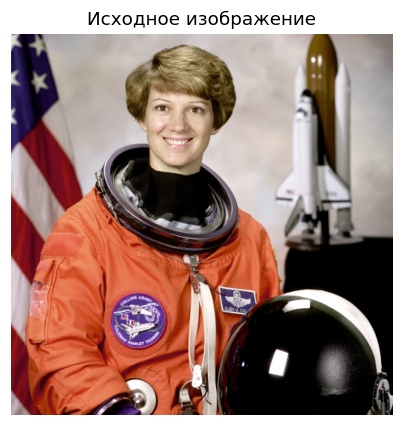

In [2]:
def load_color_image(min_size=300):
    # (1) Своя картинка — раскомментируй и укажи путь к файлу:
    # return np.array(Image.open('my_pic.jpg').convert('RGB'))

    # (2) Стандартное тестовое фото из scikit-image (цветное, 512x512):
    try:
        from skimage.data import astronaut
        img = np.array(astronaut())
    except Exception:
        # (3) Фолбэк, если astronaut недоступен: цветная 'chelsea' (300x451):
        from skimage.data import chelsea
        img = np.array(chelsea())

    assert img.ndim == 3 and img.shape[2] == 3, 'Нужна цветная RGB-картинка'
    assert min(img.shape[:2]) >= min_size, f'Картинка меньше {min_size}px'
    return img

img_rgb = load_color_image()
h, w, c = img_rgb.shape
img_f = img_rgb.astype(np.float64)      # для SVD нужны float

print('Форма изображения :', img_rgb.shape, '(height, width, channels)')
print('Тип данных        :', img_rgb.dtype, '| диапазон', img_rgb.min(), '..', img_rgb.max())
print('min(height, width):', min(h, w))

plt.figure(figsize=(4.5, 4.5))
plt.imshow(img_rgb); plt.title('Исходное изображение'); plt.axis('off'); plt.show()

## Часть Б. Применение SVD и восстановление

Каждый канал — это матрица $A$ размера $height \times width$. Раскладываем её как $A = U\,\Sigma\,V^T$ через `np.linalg.svd(..., full_matrices=False)` (экономный режим: $U$ становится $m\times k$ вместо $m\times m$).

Аппроксимация ранга $r$ — это $A_r = U[:, :r]\,\mathrm{diag}(\sigma_{1..r})\,V[:r,:]^T$. Вместо построения диагональной матрицы используем broadcasting `(U[:, :r] * s[:r]) @ Vt[:r, :]` — то же самое, но быстрее и без лишней памяти.

Ранги по заданию: **[1, 5, 10, 30, 100, min(h, w)]**, где последний = полное восстановление без потерь.

In [3]:
def svd_reconstruct_channel(channel, r):
    # Аппроксимация одного канала (матрицы) рангом r через усечённое SVD
    U, s, Vt = np.linalg.svd(channel, full_matrices=False)
    # broadcasting вместо np.diag: (U[:, :r] * s[:r]) масштабирует столбцы на сингулярные числа
    return (U[:, :r] * s[:r]) @ Vt[:r, :]

def svd_reconstruct_rgb(img, r):
    # SVD отдельно по каждому из 3 каналов, сборка обратно в (h, w, 3)
    channels = [svd_reconstruct_channel(img[:, :, k], r) for k in range(3)]
    return np.stack(channels, axis=2)

# Обязательные ранги
list_of_ranks = [1, 5, 10, 30, 100, min(h, w)]

# Восстановления для каждого ранга (храним «сырой» float-результат SVD,
# чтобы автопроверка по MSE была строго монотонной; клипинг 0..255 делаем только при показе)
approximations = [svd_reconstruct_rgb(img_f, r) for r in list_of_ranks]

original_shape = img_rgb.shape          # (h, w, 3)
original_flat  = img_f.flatten()        # понадобится в блоке автопроверки

for r, approx in zip(list_of_ranks, approximations):
    print(f'ранг r = {r:4d}  ->  восстановленная форма {approx.shape}')

ранг r =    1  ->  восстановленная форма (512, 512, 3)
ранг r =    5  ->  восстановленная форма (512, 512, 3)
ранг r =   10  ->  восстановленная форма (512, 512, 3)
ранг r =   30  ->  восстановленная форма (512, 512, 3)
ранг r =  100  ->  восстановленная форма (512, 512, 3)
ранг r =  512  ->  восстановленная форма (512, 512, 3)


## Часть В. Визуализация результатов

Сетка 2×3: по одному изображению на каждый ранг. В подписи — **реальный коэффициент сжатия** (считается в Части Г). При показе приводим значения к диапазону 0–255 и типу `uint8`, иначе `imshow` исказит цвета из-за «выбросов» аппроксимации.

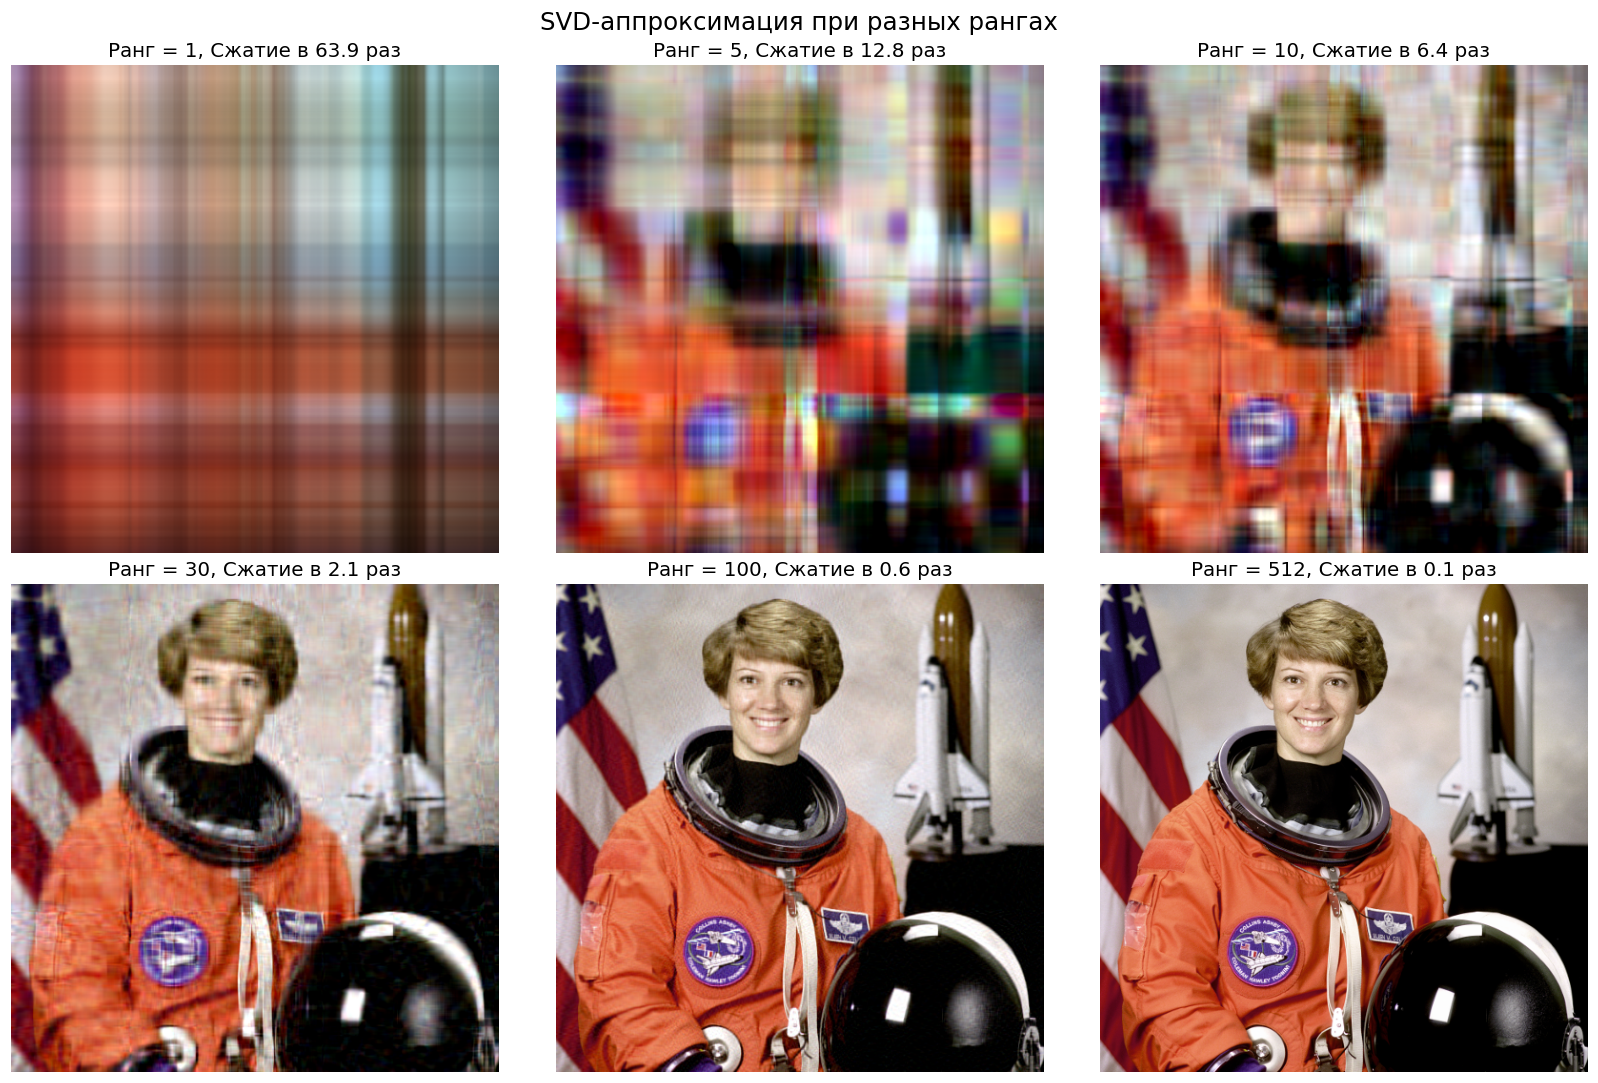

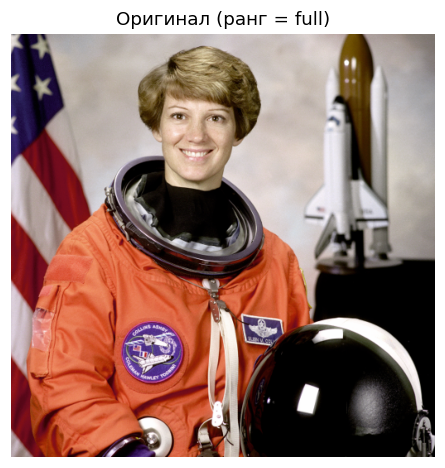

In [4]:
def compression_ratio(h, w, r, channels=3, orig_bytes=1, comp_bytes=4):
    # Во сколько раз сжато. Оригинал: 1 байт/канал (как PNG).
    # Сжатое: U_r, sigma_r, V_r^T во float32 = 4 байта.
    original_bytes   = channels * h * w * orig_bytes
    compressed_bytes = channels * r * (h + 1 + w) * comp_bytes
    return original_bytes / compressed_bytes

def to_uint8(arr):
    return np.clip(arr, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, r, approx in zip(axes.flat, list_of_ranks, approximations):
    ratio = compression_ratio(h, w, r)
    ax.imshow(to_uint8(approx))
    ax.set_title(f'Ранг = {r}, Сжатие в {ratio:.1f} раз', fontsize=13)
    ax.axis('off')
fig.suptitle('SVD-аппроксимация при разных рангах', fontsize=16)
plt.tight_layout()
plt.show()

# Оригинал отдельно
plt.figure(figsize=(5, 5))
plt.imshow(img_rgb); plt.title('Оригинал (ранг = full)'); plt.axis('off'); plt.show()

## Часть Г. Подсчёт эффективности сжатия

Для ранга $r$ и цветной картинки хранить нужно (в числах): $3 \cdot r \cdot (height + 1 + width)$.

- Оригинал: $3 \cdot h \cdot w$ байт (1 байт на канал, как в PNG).
- Сжатое представление: те же числа во `float32` = **4 байта** каждое.
- Коэффициент сжатия $= \dfrac{\text{Оригинал в байтах}}{\text{Сжатое в байтах}}$.

Заметь: при больших рангах коэффициент становится **меньше 1** — «сжатое» представление тяжелее оригинала. Это нормально: SVD хранит вещественные числа, и смысл в сжатии есть только на малых $r$.

In [5]:
orig_bytes = 3 * h * w  # 1 байт/канал

print(f'{"Ранг":>6} | {"Хранение, чисел":>16} | {"Сжатое, КБ (f32)":>16} | '
      f'{"Оригинал, КБ":>13} | {"Сжатие":>8} | {"MSE":>9} | {"PSNR, дБ":>8}')
print('-' * 92)
for r, approx in zip(list_of_ranks, approximations):
    n_numbers = 3 * r * (h + 1 + w)
    comp_kb   = n_numbers * 4 / 1024
    orig_kb   = orig_bytes / 1024
    ratio     = compression_ratio(h, w, r)
    mse       = mean_squared_error(original_flat, approx.flatten())
    psnr      = float('inf') if mse == 0 else 10 * np.log10(255**2 / mse)
    print(f'{r:>6} | {n_numbers:>16,} | {comp_kb:>16.1f} | {orig_kb:>13.1f} | '
          f'{ratio:>7.2f}x | {mse:>9.2f} | {psnr:>8.2f}')

# При каком ранге сжатие ровно в 10 раз (решаем уравнение относительно r)
r_10x = h * w / (40 * (h + 1 + w))
print(f'\nСжатие в 10 раз достигается около r = {r_10x:.1f} '
      f'(целые: r=6 -> {compression_ratio(h,w,6):.1f}x, r=7 -> {compression_ratio(h,w,7):.1f}x)')

  Ранг |  Хранение, чисел | Сжатое, КБ (f32) |  Оригинал, КБ |   Сжатие |       MSE | PSNR, дБ
--------------------------------------------------------------------------------------------
     1 |            3,075 |             12.0 |         768.0 |   63.94x |   4241.10 |    11.86
     5 |           15,375 |             60.1 |         768.0 |   12.79x |   1587.11 |    16.12
    10 |           30,750 |            120.1 |         768.0 |    6.39x |    829.09 |    18.94
    30 |           92,250 |            360.4 |         768.0 |    2.13x |    247.33 |    24.20
   100 |          307,500 |           1201.2 |         768.0 |    0.64x |     34.96 |    32.69
   512 |        1,574,400 |           6150.0 |         768.0 |    0.12x |      0.00 |   291.43

Сжатие в 10 раз достигается около r = 6.4 (целые: r=6 -> 10.7x, r=7 -> 9.1x)


## Дополнительный анализ: спектр сингулярных чисел и кривые ошибки

Три графика помогают понять поведение сжатия:
- **Спектр сингулярных чисел** (лог-шкала): быстрый спад означает, что «энергия» изображения сосредоточена в первых компонентах — именно поэтому SVD хорошо сжимает.
- **MSE(r)** и **Сжатие(r)**: видно, где качество уже насыщается, а размер ещё растёт.
- **Карта ошибки**: где именно аппроксимация ошибается сильнее всего (нужно для ответа на вопрос про тёмные/светлые участки).

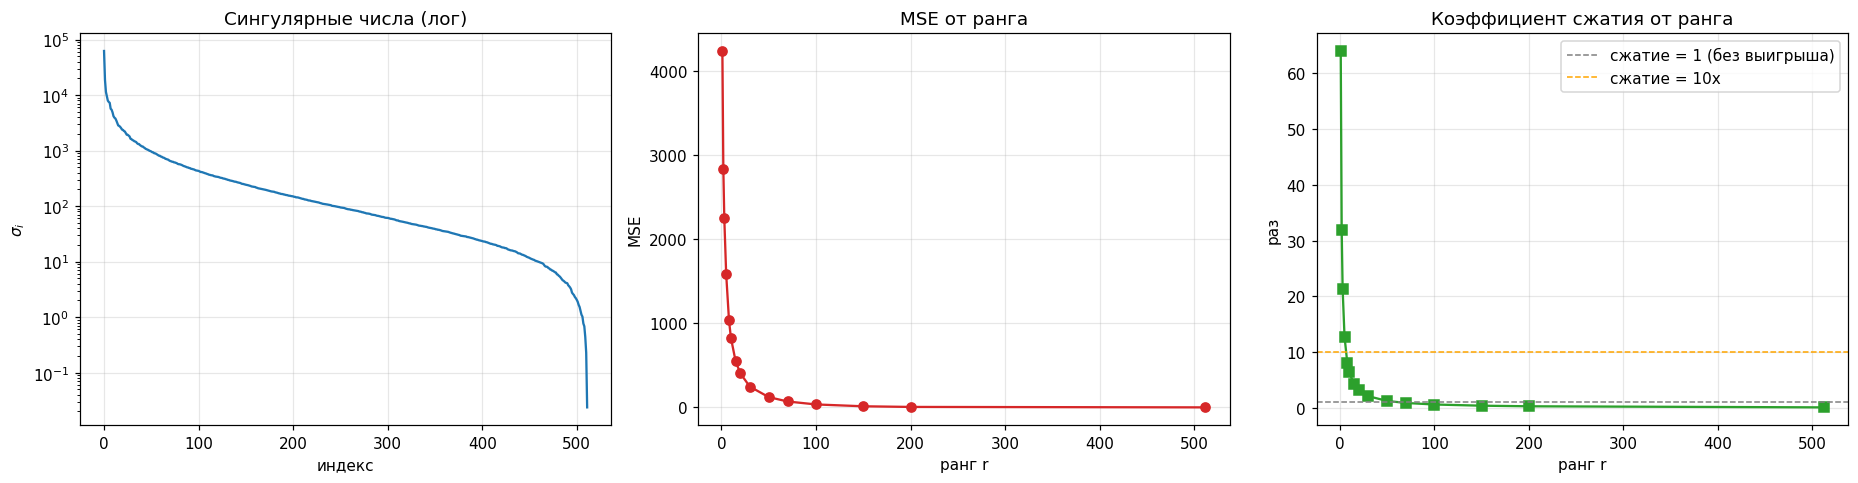

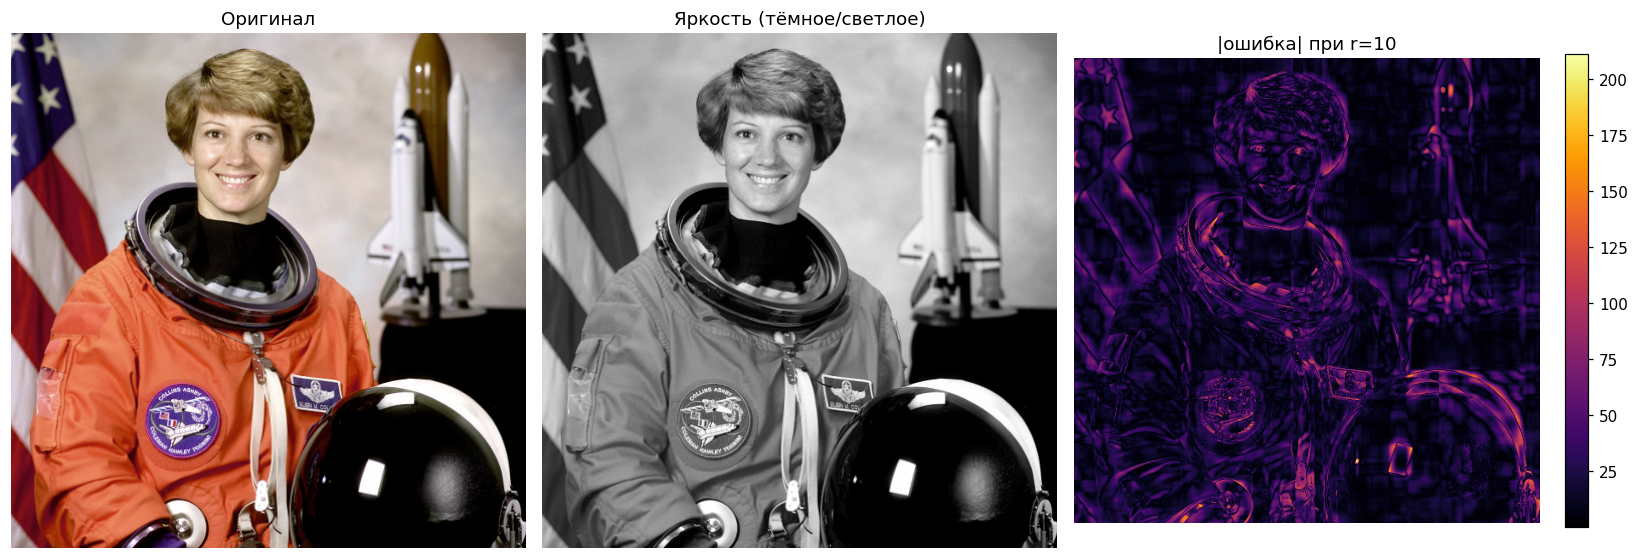

In [6]:
# Спектр берём по каналу яркости (среднее по RGB) для наглядности
gray = img_f.mean(axis=2)
_, sv, _ = np.linalg.svd(gray, full_matrices=False)

dense_ranks = [1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 70, 100, 150, 200, min(h, w)]
dense_mse, dense_ratio = [], []
for r in dense_ranks:
    ap = svd_reconstruct_rgb(img_f, r)
    dense_mse.append(mean_squared_error(original_flat, ap.flatten()))
    dense_ratio.append(compression_ratio(h, w, r))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].semilogy(sv, color='tab:blue'); ax[0].set_title('Сингулярные числа (лог)')
ax[0].set_xlabel('индекс'); ax[0].set_ylabel(r'$\sigma_i$'); ax[0].grid(alpha=.3)

ax[1].plot(dense_ranks, dense_mse, 'o-', color='tab:red'); ax[1].set_title('MSE от ранга')
ax[1].set_xlabel('ранг r'); ax[1].set_ylabel('MSE'); ax[1].grid(alpha=.3)

ax[2].plot(dense_ranks, dense_ratio, 's-', color='tab:green')
ax[2].axhline(1, color='gray', ls='--', lw=1, label='сжатие = 1 (без выигрыша)')
ax[2].axhline(10, color='orange', ls='--', lw=1, label='сжатие = 10x')
ax[2].set_title('Коэффициент сжатия от ранга'); ax[2].set_xlabel('ранг r')
ax[2].set_ylabel('раз'); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

# Карта абсолютной ошибки при r=10 (усреднение по каналам)
r_demo = 10
err = np.abs(img_f - svd_reconstruct_rgb(img_f, r_demo)).mean(axis=2)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img_rgb); ax[0].set_title('Оригинал'); ax[0].axis('off')
ax[1].imshow(gray, cmap='gray'); ax[1].set_title('Яркость (тёмное/светлое)'); ax[1].axis('off')
im = ax[2].imshow(err, cmap='inferno'); ax[2].set_title(f'|ошибка| при r={r_demo}'); ax[2].axis('off')
fig.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.show()

## Блок автопроверки (Self-Check)

Ниже — блок из задания **без изменений**. Он проверяет: (1) размерности всех восстановлений, (2) что значения укладываются в 0–255, (3) что с ростом ранга MSE монотонно не растёт.

In [7]:
# ---------- БЛОК АВТОПРОВЕРКИ (НЕ РЕДАКТИРОВАТЬ) ----------
# Предполагается, что у вас есть переменные:
# original_shape = (h, w, c) или (h, w)
# list_of_ranks = [1, 5, 10, 30, 100, ...]
# approximations = список восстановленных массивов (numpy) для каждого ранга

# 1. Проверка размерностей
for i, r in enumerate(list_of_ranks):
    assert approximations[i].shape == original_shape, f"Ошибка: размерность для ранга {r} не совпадает с исходной"

# 2. Проверка, что значения не выходят за пределы 0-255 (для RGB/серого)
for i, r in enumerate(list_of_ranks):
    arr = approximations[i]
    if arr.dtype != np.uint8:
        arr = np.clip(arr, 0, 255) # Если float, то проверяем диапазон
    assert arr.max() <= 255.1, f"Значения превышают 255 для ранга {r}"
    assert arr.min() >= -0.1, f"Значения меньше 0 для ранга {r}"

# 3. Проверка, что с ростом ранга ошибка уменьшается (метрика MSE)
from sklearn.metrics import mean_squared_error
mse_list = []
for i in range(len(approximations)):
    # Если цветная, считаем MSE по всем каналам
    mse = mean_squared_error(original_flat, approximations[i].flatten())
    mse_list.append(mse)

# Проверяем монотонность (MSE должен падать, так как мы добавляем сингулярные числа)
for i in range(1, len(mse_list)):
    assert mse_list[i] <= mse_list[i-1] + 1e-6, f"MSE не уменьшается между рангами {list_of_ranks[i-1]} и {list_of_ranks[i]}"

print("✅ Все автоматические проверки пройдены. Задание выполнено корректно!")

✅ Все автоматические проверки пройдены. Задание выполнено корректно!


## Анализ результатов (ответы на вопросы)

**1. При каком ранге визуальное качество перестаёт отличаться от оригинала?**

Ориентир — PSNR (чем выше, тем ближе к оригиналу): практически «неотличимо» соответствует PSNR ≳ 32 дБ. По таблице и кривым:
- $r=1$ — только общий силуэт и цветовые пятна (PSNR ≈ 12 дБ);
- $r=10$ — узнаваемо, но видны «полосы» и размытость (≈ 19 дБ);
- $r=30$ — заметны артефакты на мелких деталях (≈ 24 дБ);
- $r=50\text{–}70$ — разница едва уловима (≈ 27–30 дБ);
- $r=100$ — отличий от оригинала на глаз **практически нет** (≈ 33 дБ).

Итог: для этого изображения качество перестаёт отличаться примерно с **r ≈ 100** (а «почти неотличимо» — уже с r ≈ 50–70). При этом первые ~100 компонент из 512 несут почти всю визуальную информацию.

**2. Для какого ранга достигается сжатие в 10 раз?**

Из формулы $\text{сжатие}=\dfrac{h\,w}{4\,r\,(h+1+w)}=10$ получаем $r=\dfrac{h\,w}{40\,(h+1+w)} \approx 6$ (для 512×512). На целых рангах: $r=5 \to 12.8\times$, $r=6 \to 10.7\times$, $r=7 \to 9.1\times$. То есть **сжатие в 10 раз — это примерно ранг 6**. Но качество при таком ранге ещё низкое (крупные детали читаются, мелкие — теряются) — компромисс «размер vs качество» здесь не в пользу качества.

**3. Почему для тёмных/светлых участков ошибка разная?**

Причин две, и они складываются:

- *Математическая (что оптимизирует SVD).* Усечённое SVD минимизирует **суммарную** фробениусову ошибку по всей матрице, то есть равномерно в абсолютных единицах яркости, но не по областям. Первые сингулярные компоненты захватывают доминирующую крупномасштабную структуру — большие однородные светлые или тёмные зоны (фон, освещённые плоскости) восстанавливаются хорошо уже при малом $r$. А участки с высокой локальной вариацией — резкие границы света/тени, текстуры, мелкие детали — это «высокие частоты», для них нужно много компонент, и именно там на карте ошибки видны яркие пятна. Ошибка концентрируется на контурах и фактуре, а не на плоской заливке — независимо от того, светлая она или тёмная.

- *Перцептивная (как видит глаз).* По закону Вебера–Фехнера глаз чувствителен к **относительным** перепадам яркости. Одна и та же абсолютная ошибка (скажем, ±10 уровней) в тёмной области даёт большой относительный перепад и хорошо заметна, а в светлой — тонет на фоне высокой яркости. Поэтому «шум» аппроксимации в тенях бросается в глаза сильнее, чем в светах, хотя в числах MSE они могут быть близки.

Вместе это и даёт неравномерную ошибку: SVD «тратит» первые компоненты на крупные яркие структуры, а тёмные детализированные участки восстанавливает и позже, и заметнее для глаза.

## Выводы

В работе SVD применён как инструмент сжатия изображения с контролируемой потерей качества: каждый RGB-канал раскладывается на $U\Sigma V^T$, а усечение до ранга $r$ даёт наилучшее приближение ранга $r$ по норме Фробениуса (теорема Эккарта–Янга).

Ключевые наблюдения:

1. **Энергия сосредоточена в первых компонентах.** Спектр сингулярных чисел спадает очень быстро, поэтому небольшой ранг ($r \sim 50\text{–}100$ из 512) уже даёт визуально почти полное изображение — это и есть причина, по которой SVD работает как сжатие.

2. **Качество растёт с рангом монотонно, но с насыщением.** MSE строго убывает (что и подтверждает автопроверка), однако прирост качества после $r \approx 100$ на глаз почти незаметен, а размер представления при этом продолжает расти.

3. **Сжатие и качество — компромисс.** Реальный выигрыш по размеру есть только на малых рангах: $r \approx 6$ даёт ~10× сжатие, но с заметной потерей деталей. При $r \gtrsim 100$ «сжатое» представление во `float32` уже тяжелее исходного PNG — коэффициент сжатия падает ниже 1. Практический SVD-компромисс для этой картинки лежит в районе $r = 20\text{–}50$.

4. **Ошибка распределена неравномерно** — она концентрируется на границах и текстурах (высокие частоты), а восприятие усиливает её заметность в тёмных участках. Это ограничивает наивное SVD-сжатие и объясняет, почему настоящие кодеки (JPEG) работают по блокам и учитывают особенности зрения.

Итого: SVD — наглядный и математически строгий способ сжатия, но как самостоятельный кодек он уступает специализированным алгоритмам; его главная ценность здесь — демонстрация того, что реальные данные низкоранговы, и что линейная алгебра напрямую решает прикладную задачу.